**Week 8**<br />Friday, Oct. 23

# Tagging

LX 394/694<br />
Coding for Linguists

Sophie Hao


## Announcements

- We are now starting Chapter 5 of the textbook (Tagging).
- This is the first computational linguistics topic we are covering.
- **No class next week**
- [Volunteer for BUCLD](https://docs.google.com/forms/d/e/1FAIpQLSffK9w5w7DP82wj7OYOHfhJVGcPN3U1VVzrVHka1lapVN9IWg/viewform) instead!
- How is HW 2 going?

## Recap: Tokenization

**Tokenization** is the process of splitting a string into tokens.

In [1]:
# NLTK's default tokenizer
from nltk import word_tokenize

In [2]:
word_tokenize("The quick brown fox jumps over the lazy dog.")

['The', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog', '.']

## Recap: Regexes

**Regular expressions** ("regexes") allow us to describe **patterns** within a string.

```python
r"\w+|\."         # A sequence of alphanumerics or .
r"\w+|[\.,!?;]"   # A sequence of alphanumerics or .,!?;
```

In [3]:
import re

text = "  The quick   brown fox\n jumps over the lazy dog?!"
re.findall(r"\w+|[\.,!?;]", text)

['The',
 'quick',
 'brown',
 'fox',
 'jumps',
 'over',
 'the',
 'lazy',
 'dog',
 '?',
 '!']

## Application: Form Input Validation

If `\d` represents a digit (0–9), what do the following regexes mean?

```python
r"1-\d\d\d-\d\d\d-\d\d\d\d"
r"\w+@\w+\.\w+"
```

In [4]:
# Is this a valid phone number?
bool(re.fullmatch(r"1-\d\d\d-\d\d\d-\d\d\d\d", "123-456-7890"))

False

In [5]:
bool(re.fullmatch(r"1-\d\d\d-\d\d\d-\d\d\d\d", "1-123-456-7890"))

True

In [6]:
bool(re.fullmatch(r"\w+@\w+\.\w+", "uu@bu.edu"))

True

## Example: Command Line Form

Python's `input` function prompts the user to type something into the command line.

In [8]:
email = input("What is your email address? ")
print(f"Great, I'll send an email to {email}.")

What is your email address? sophie@notaphonologist.com
Great, I'll send an email to sophie@notaphonologist.com.


## Example: Form With Validation

In [9]:
is_valid = False
while not is_valid:
    email = input("What is your email address? ")
    if re.fullmatch(r"\w+@\w+\.\w+", email):
        is_valid = True
        print(f"Great, I'll send an email to {email}.")
    else:
        print("That's not a valid email address.")

What is your email address? sdlkewflkewflkl
That's not a valid email address.
What is your email address? 1-234-567-8910
That's not a valid email address.
What is your email address? uu@bu.edu
Great, I'll send an email to uu@bu.edu.


## Word Segmentation

**Word segmentation** is often done in languages with no word boundaries.

**Example:** How would you segment `'小笼包'`?
- `['小笼包']`
- `['小', '笼包']`
- `['小笼', '包']`
- `['小', '笼', '包']`

![A serving of xiaolongbao](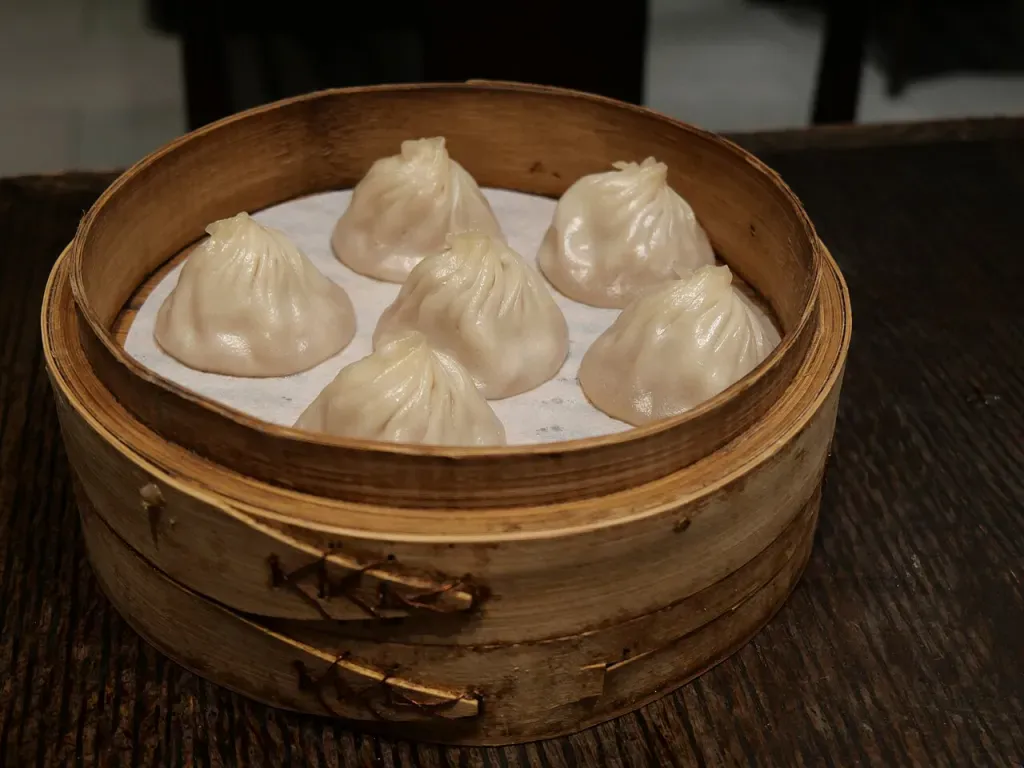 "A serving of xiaolongbao")

<span style="color: #cccccc">From <a href="https://commons.wikimedia.org/wiki/File:A_Xiaolongbao_from_The_Modern_Shanghai.jpg" style="color: #cccccc">Wikimedia Commons</a>

## Byte-Pair Tokenization

ChatGPT uses **byte-pair tokenization**, a method in which you build a **vocabulary** by combining frequent sequences.

```python
vocab = {"a", "b", ...}
while len(vocab) < n:
    a, b = ...  # The most common bigram in a corpus
    vocab.add(a + b)
```

## Bytes as Tokens

The starting vocabulary is the set of all UTF-8 bytes in the corpus.

**Example:** [GPT-4o](https://platform.openai.com/tokenizer) treats `'小笼包'` as **4 tokens**. 
- The UTF-8 representation of 笼 is E7 AC BC (11100111 10101100 10111100)
- The GPT-4o tokenization of `'小笼包'` is either:
   - `['小', '\xE7', '\xAC\xBC', '包']` or
   - `['小', '\xE7\xAC', '\xBC', '包']`

## Tagging

**Tagging** is an NLP task in which each token in a text gets assigned a **tag.**

**Example:** Part of speech (POS) tagging

In [10]:
import nltk
nltk.download('averaged_perceptron_tagger_eng')

text = nltk.word_tokenize("The quick brown fox jumps over the lazy dog.")
nltk.pos_tag(text)

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/sophie/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


[('The', 'DT'),
 ('quick', 'JJ'),
 ('brown', 'NN'),
 ('fox', 'NN'),
 ('jumps', 'VBZ'),
 ('over', 'IN'),
 ('the', 'DT'),
 ('lazy', 'JJ'),
 ('dog', 'NN'),
 ('.', '.')]

In [11]:
nltk.pos_tag(text)

[('The', 'DT'),
 ('quick', 'JJ'),
 ('brown', 'NN'),
 ('fox', 'NN'),
 ('jumps', 'VBZ'),
 ('over', 'IN'),
 ('the', 'DT'),
 ('lazy', 'JJ'),
 ('dog', 'NN'),
 ('.', '.')]

| Tag | Description | Tag | Description |
|-----|-------------|-----|-------------|
| `DT`  | Determiner  | `VBZ` | Verb, 3rd person singular present |
| `JJ`  | Adjective   | `IN`  | Preposition or subordinating conjunction |
| `NN`  | Noun, singular or mass | `.` | Period |

[See full list of tags](https://www.ling.upenn.edu/courses/Fall_2003/ling001/penn_treebank_pos.html)

## How Do You Do POS Tagging?

Simple method: have a `dict` with the POS tag for each token, and just look it up.

```python
class Tagger:
    def __init__(self):
        self.tags = {"The": "DT", "quick": "JJ", "brown": "NN", ...}

    def get_tag(self, w):
        return self.tags[w] if w in self.tags else w
        
    def tag(self, text):
        return [(w, self.get_tag(w)) for w in text]
```

## Regex Tagger

In [12]:
patterns = [
    (r'.*ing$', 'VBG'),                # gerunds
    (r'.*ed$', 'VBD'),                 # simple past
    (r'.*es$', 'VBZ'),                 # 3rd singular present
    (r'.*ould$', 'MD'),                # modals
    (r'.*\'s$', 'NN$'),                # possessive nouns
    (r'.*s$', 'NNS'),                  # plural nouns
    (r'^-?[0-9]+(\.[0-9]+)?$', 'CD'),  # cardinal numbers
    (r'.*', 'NN')                      # nouns (default)
]

In [13]:
tagger = nltk.RegexpTagger(patterns)
text = nltk.word_tokenize("I would have liked to be wearing shoes in the rain.")
tagger.tag(text)

[('I', 'NN'),
 ('would', 'MD'),
 ('have', 'NN'),
 ('liked', 'VBD'),
 ('to', 'NN'),
 ('be', 'NN'),
 ('wearing', 'VBG'),
 ('shoes', 'VBZ'),
 ('in', 'NN'),
 ('the', 'NN'),
 ('rain', 'NN'),
 ('.', 'NN')]

## Problems

What are some problems with the simple tagger and the regex tagger?

How might we fix those problems?

## Next Time

Tagging with Machine Learning